In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

df = pd.read_csv("insurance.csv")

display(df.head())

print("Dataset shape:", df.shape)

df.info()

display(df.describe(include="all"))

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Dataset shape: (1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


In [3]:
print("Missing values per column:")
print(df.isnull().sum())

print("Number of duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

categorical_columns = ["sex", "smoker", "region"]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts())

display(df.describe())

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Number of duplicate rows: 1

Data types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

sex:
sex
male      676
female    662
Name: count, dtype: int64

smoker:
smoker
no     1064
yes     274
Name: count, dtype: int64

region:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


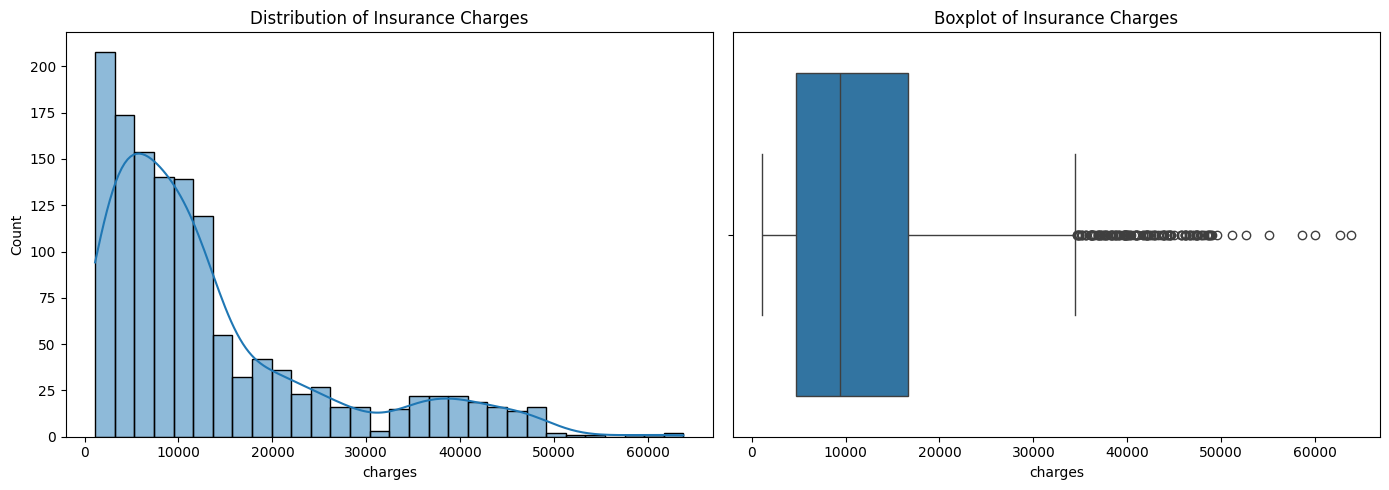

Mean charges: 13270.422265141257
Median charges: 9382.033
Skewness: 1.5158796580240388


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["charges"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of Insurance Charges")

sns.boxplot(x=df["charges"], ax=axes[1])
axes[1].set_title("Boxplot of Insurance Charges")

plt.tight_layout()
plt.show()

print("Mean charges:", df["charges"].mean())
print("Median charges:", df["charges"].median())
print("Skewness:", df["charges"].skew())

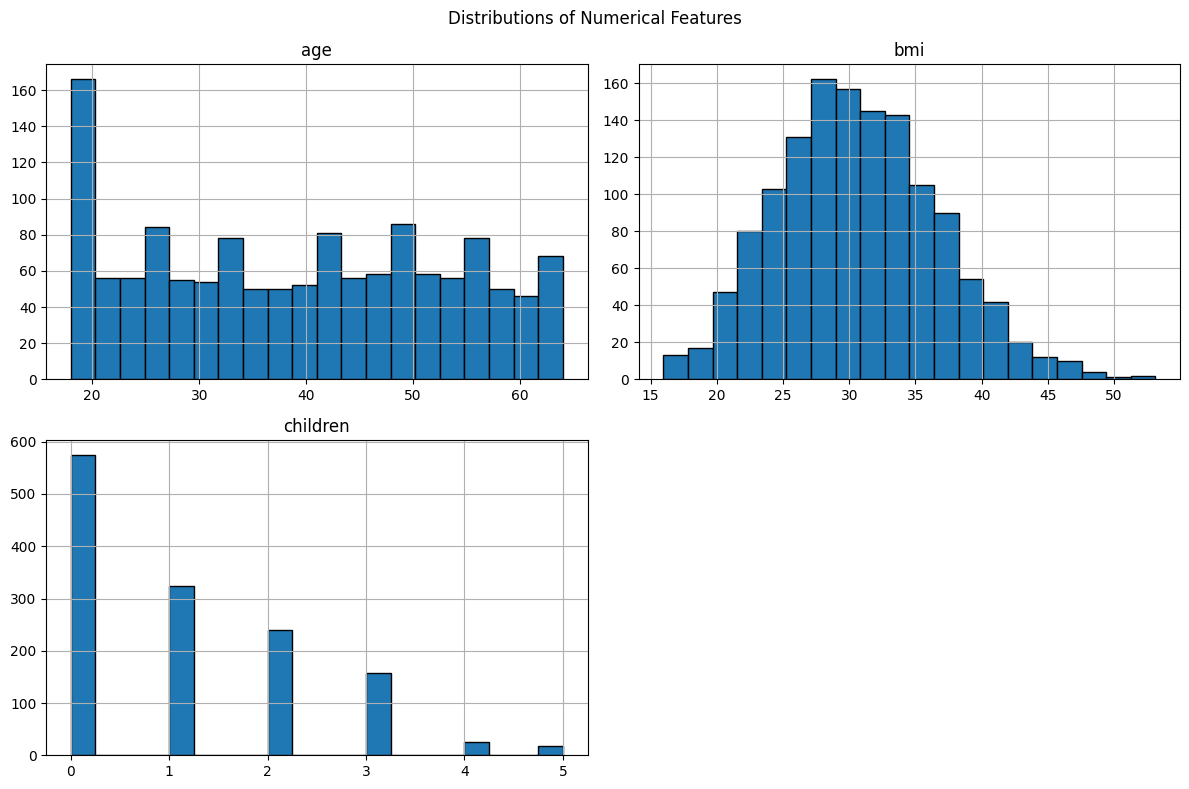

In [5]:
numerical_features = ["age", "bmi", "children"]

df[numerical_features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distributions of Numerical Features")
plt.tight_layout()
plt.show()

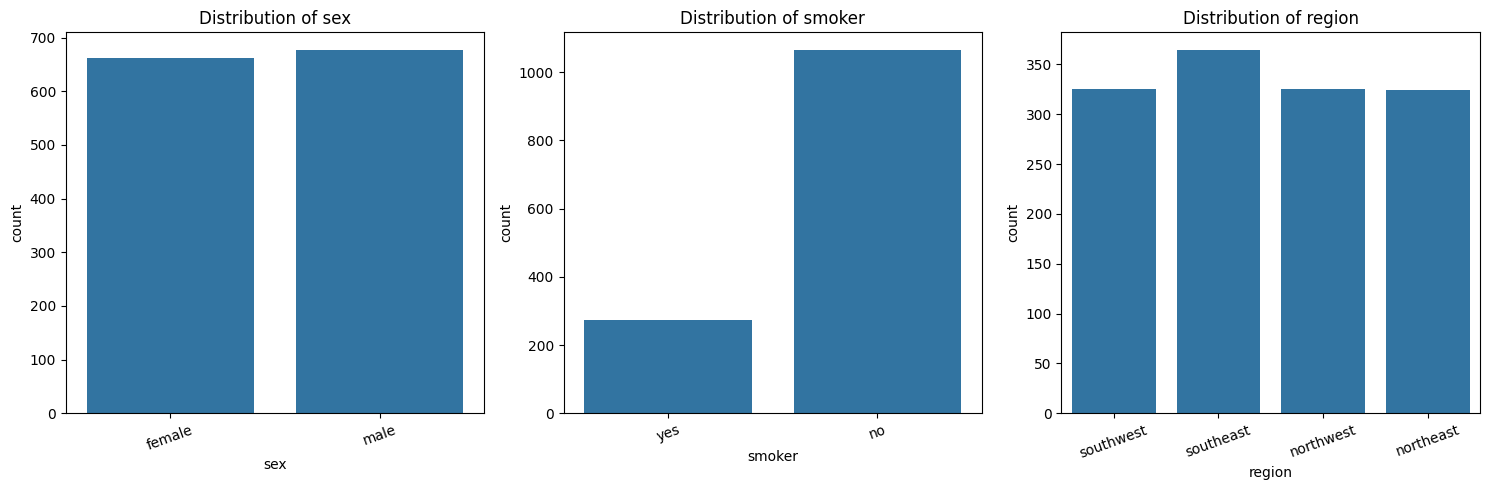

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, column in zip(axes, categorical_columns):
    sns.countplot(data=df, x=column, ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

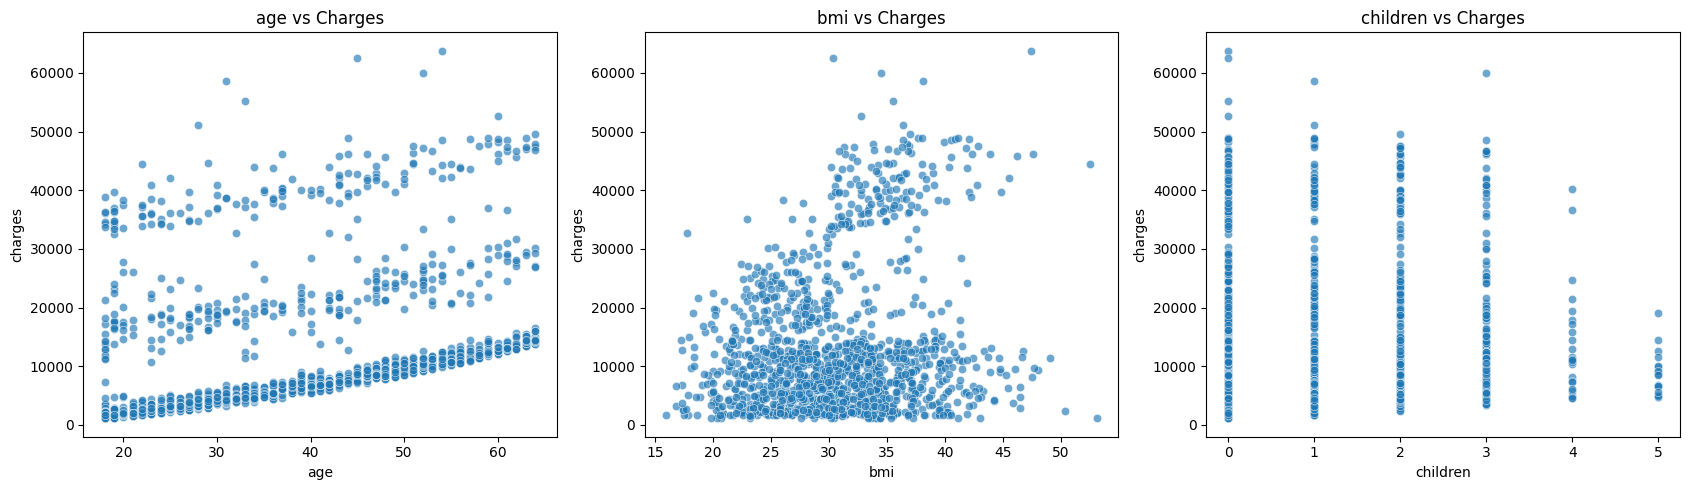

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, feature in zip(axes, numerical_features):
    sns.scatterplot(
        data=df,
        x=feature,
        y="charges",
        ax=ax,
        alpha=0.65
    )
    ax.set_title(f"{feature} vs Charges")

plt.tight_layout()
plt.show()

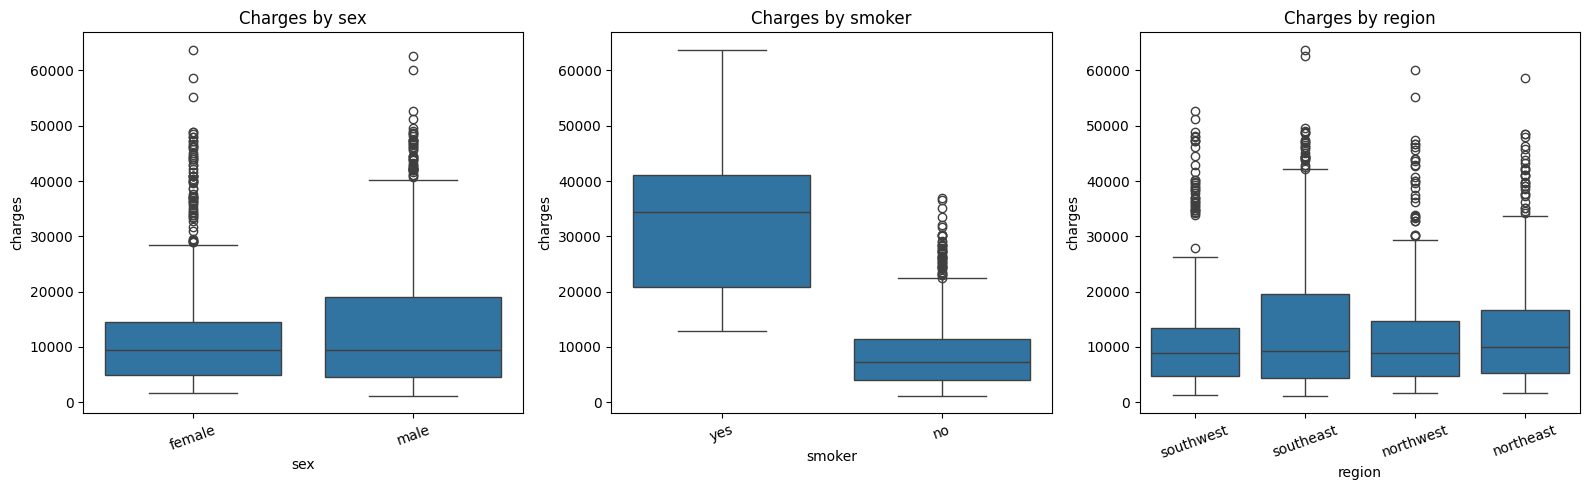

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, categorical_columns):
    sns.boxplot(
        data=df,
        x=feature,
        y="charges",
        ax=ax
    )
    ax.set_title(f"Charges by {feature}")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

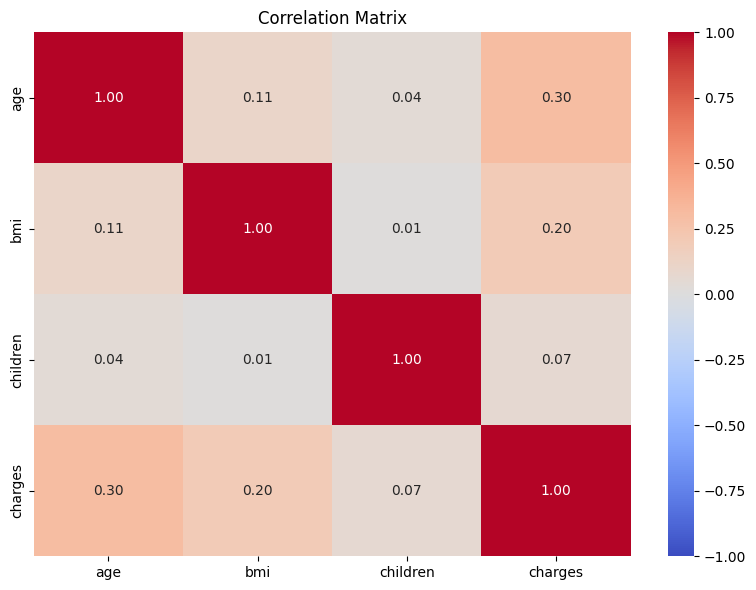

In [9]:
correlation_matrix = df[
    ["age", "bmi", "children", "charges"]
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [10]:
X = df.drop(columns=["charges"])
y = df["charges"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (1338, 6)
Target shape: (1338,)


,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1070, 6)
Testing features: (268, 6)
Training target: (1070,)
Testing target: (268,)


In [12]:
numerical_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

In [13]:
def create_preprocessor():
    numerical_transformer = StandardScaler()

    categorical_transformer = OneHotEncoder(
        handle_unknown="ignore"
    )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                numerical_transformer,
                numerical_features
            ),
            (
                "cat",
                categorical_transformer,
                categorical_features
            )
        ]
    )

    return preprocessor

In [14]:
models = {
    "Linear Regression": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", Ridge(alpha=1.0))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", create_preprocessor()),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ])
}

In [15]:
predictions = {}
results = []

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    predictions[name] = y_pred
    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="RMSE",
        ascending=True
    ).reset_index(drop=True)
)

,Model,MAE,RMSE,R2
0,Random Forest,2529.343571,4587.539559,0.864440
1,Linear Regression,4181.194474,5796.284659,0.783593
2,Ridge Regression,4186.913072,5798.298795,0.783443


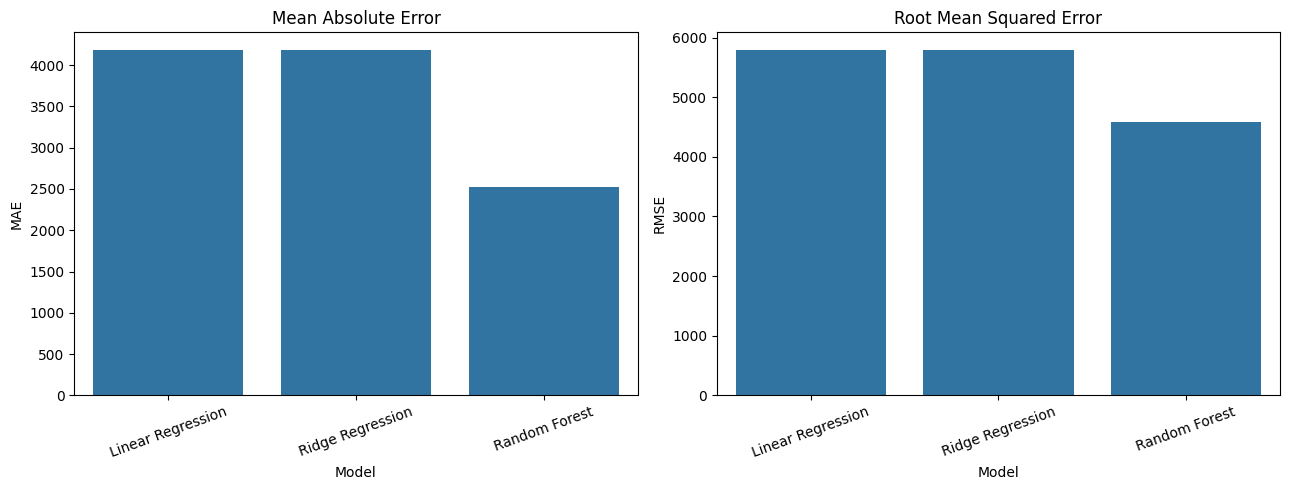

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE",
    ax=axes[0]
)
axes[0].set_title("Mean Absolute Error")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE",
    ax=axes[1]
)
axes[1].set_title("Root Mean Squared Error")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

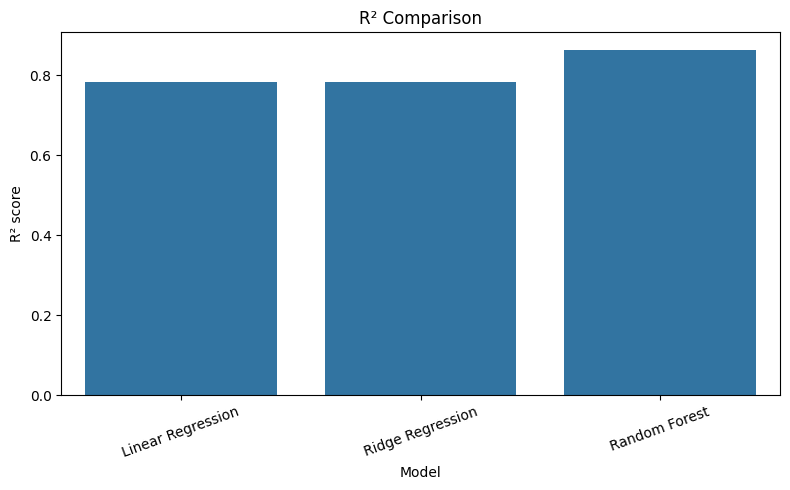

In [17]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2"
)

plt.title("R² Comparison")
plt.ylabel("R² score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

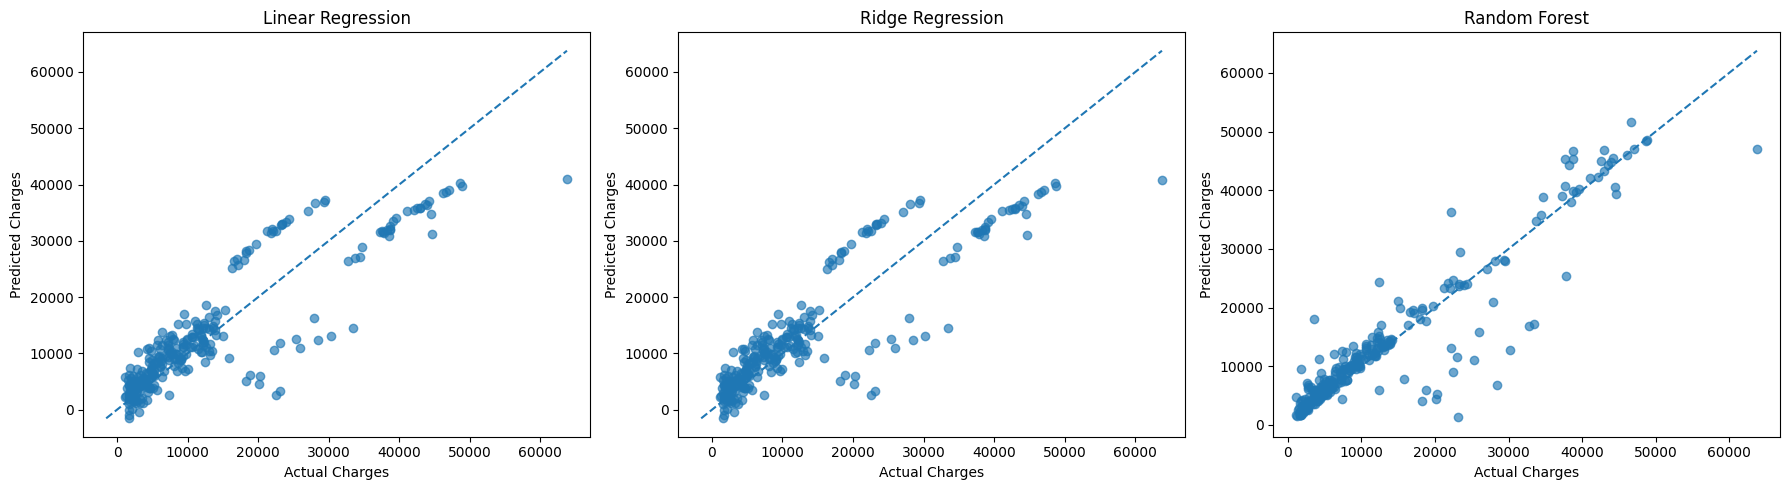

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):

    ax.scatter(
        y_test,
        y_pred,
        alpha=0.65
    )

    min_value = min(y_test.min(), y_pred.min())
    max_value = max(y_test.max(), y_pred.max())

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    ax.set_xlabel("Actual Charges")
    ax.set_ylabel("Predicted Charges")
    ax.set_title(name)

plt.tight_layout()
plt.show()

Best model by test RMSE: Random Forest


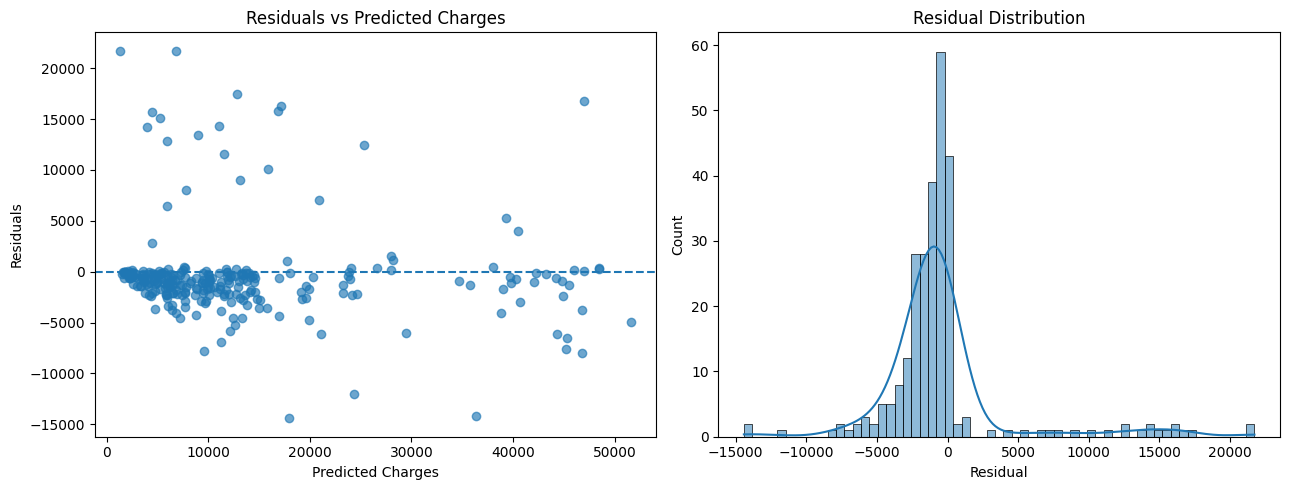

In [19]:
best_model_name = results_df.loc[
    results_df["RMSE"].idxmin(),
    "Model"
]

best_model = models[best_model_name]
best_predictions = predictions[best_model_name]

residuals = y_test - best_predictions

print("Best model by test RMSE:", best_model_name)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    best_predictions,
    residuals,
    alpha=0.65
)

axes[0].axhline(
    y=0,
    linestyle="--"
)

axes[0].set_xlabel("Predicted Charges")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Predicted Charges")

sns.histplot(
    residuals,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residual")

plt.tight_layout()
plt.show()

In [20]:
generalization_results = []

for name, pipeline in models.items():

    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)

    generalization_results.append({
        "Model": name,
        "Train MAE": mean_absolute_error(
            y_train,
            train_pred
        ),
        "Test MAE": mean_absolute_error(
            y_test,
            test_pred
        ),
        "Train RMSE": np.sqrt(
            mean_squared_error(y_train, train_pred)
        ),
        "Test RMSE": np.sqrt(
            mean_squared_error(y_test, test_pred)
        ),
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred)
    })

generalization_df = pd.DataFrame(
    generalization_results
)

display(generalization_df)

,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,4208.234572,4181.194474,6105.545160,5796.284659,0.741726,0.783593
1,Ridge Regression,4212.650075,4186.913072,6105.608877,5798.298795,0.741720,0.783443
2,Random Forest,1024.689006,2529.343571,1866.402144,4587.539559,0.975865,0.864440


In [21]:
rf_pipeline = models["Random Forest"]

fitted_preprocessor = rf_pipeline.named_steps["preprocessor"]
fitted_rf = rf_pipeline.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": fitted_rf.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

,Feature,Importance
5,cat__smoker_no,0.430350
1,num__bmi,0.210729
6,cat__smoker_yes,0.179026
0,num__age,0.134569
2,num__children,0.019641
7,cat__region_northeast,0.005295
8,cat__region_northwest,0.004521
9,cat__region_southeast,0.004243
3,cat__sex_female,0.004210
4,cat__sex_male,0.004092


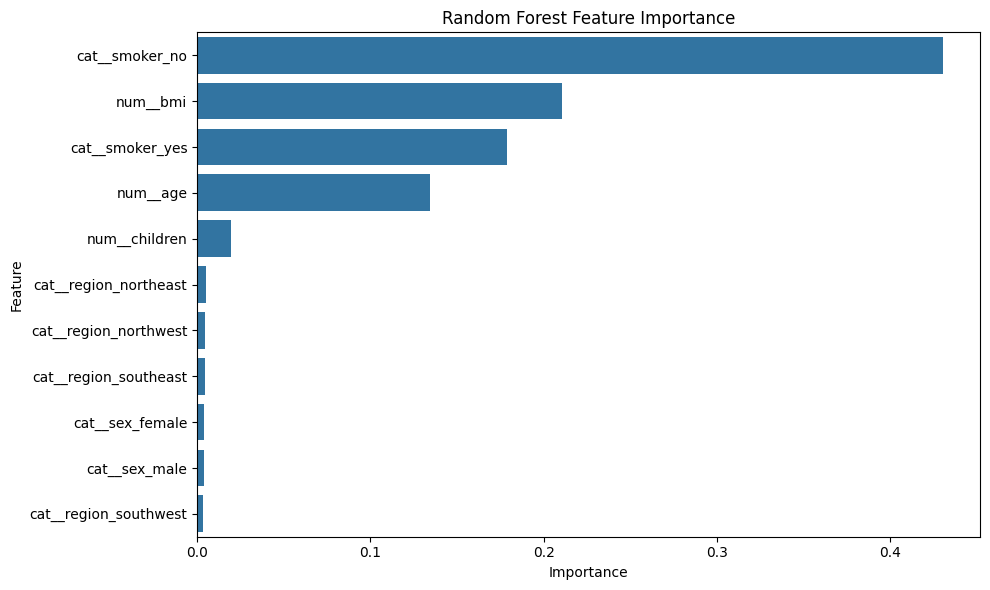

In [22]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [23]:
scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

cv_results = []

for name, pipeline in models.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append({
        "Model": name,
        "Mean CV MAE": -scores["test_mae"].mean(),
        "Mean CV RMSE": -scores["test_rmse"].mean(),
        "Mean CV R2": scores["test_r2"].mean(),
        "Std CV RMSE": scores["test_rmse"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values(
        by="Mean CV RMSE",
        ascending=True
    ).reset_index(drop=True)
)

,Model,Mean CV MAE,Mean CV RMSE,Mean CV R2,Std CV RMSE
0,Random Forest,2748.365602,4899.867524,0.828494,481.192595
1,Ridge Regression,4250.352629,6146.993987,0.733143,399.318719
2,Linear Regression,4245.227948,6147.093944,0.733110,401.406393


In [24]:
rf_pipeline = Pipeline([
    ("preprocessor", create_preprocessor()),
    (
        "model",
        RandomForestRegressor(
            random_state=42,
            n_jobs=1
        )
    )
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print(
    "Best cross-validation RMSE:",
    -grid_search.best_score_
)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 4, 'model__n_estimators': 200}
Best cross-validation RMSE: 4687.224526322997


In [25]:
tuned_model = grid_search.best_estimator_

tuned_predictions = tuned_model.predict(X_test)

tuned_mae = mean_absolute_error(
    y_test,
    tuned_predictions
)

tuned_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_predictions)
)

tuned_r2 = r2_score(
    y_test,
    tuned_predictions
)

print("Tuned Random Forest Results")
print(f"MAE:{tuned_mae:.2f}")
print(f"RMSE: {tuned_rmse:.2f}")
print(f"R²: {tuned_r2:.4f}")

Tuned Random Forest Results
MAE:2418.74
RMSE: 4349.55
R²: 0.8781


In [26]:
final_predictions = predictions.copy()

final_predictions["Tuned Random Forest"] = tuned_predictions

final_results = []

for name, y_pred in final_predictions.items():

    final_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, y_pred)
        ),
        "R2": r2_score(y_test, y_pred)
    })

final_results_df = pd.DataFrame(final_results)

display(
    final_results_df.sort_values(
        by="RMSE",
        ascending=True
    ).reset_index(drop=True)
)

,Model,MAE,RMSE,R2
0,Tuned Random Forest,2418.735695,4349.546033,0.878140
1,Random Forest,2529.343571,4587.539559,0.864440
2,Linear Regression,4181.194474,5796.284659,0.783593
3,Ridge Regression,4186.913072,5798.298795,0.783443
